<a href="https://colab.research.google.com/github/ra-jash-ree/ML-Lab-4NI24CI083/blob/main/4NI24CI083_Banknote_LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#imported libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
#dataset loading
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columns = [
    "Variance",
    "Skewness",
    "Curtosis",
    "Entropy",
    "Class"
]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head(10)
print("Dataset shape:", df.shape)


Dataset shape: (1372, 5)


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Variance  1372 non-null   float64
 1   Skewness  1372 non-null   float64
 2   Curtosis  1372 non-null   float64
 3   Entropy   1372 non-null   float64
 4   Class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())
print("Number of duplicate records:", df.duplicated().sum())

Missing values in each column:
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64
Number of duplicate records: 24


In [ ]:
df.describe()

,Variance,Skewness,Curtosis,Entropy,Class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [ ]:
#distribustion of class
print("Class counts:")
print(df["Class"].value_counts())

print("\nClass percentages:")
print(df["Class"].value_counts(normalize=True) * 100)

Class counts:
Class
0    762
1    610
Name: count, dtype: int64

Class percentages:
Class
0    55.539359
1    44.460641
Name: proportion, dtype: float64


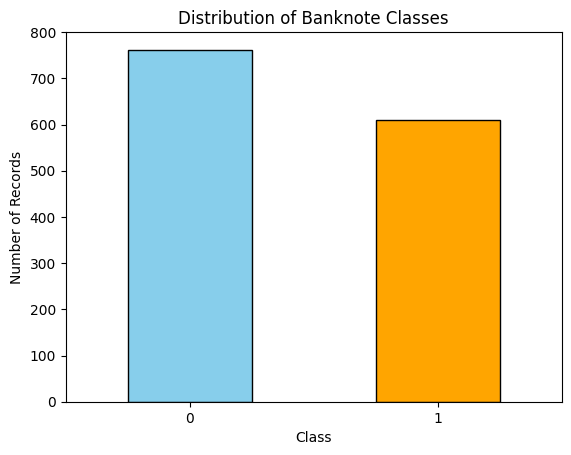

In [ ]:
#graph
df["Class"].value_counts().sort_index().plot(
    kind="bar",
    color=["skyblue", "orange"],
    edgecolor="black"
)

plt.title("Distribution of Banknote Classes")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

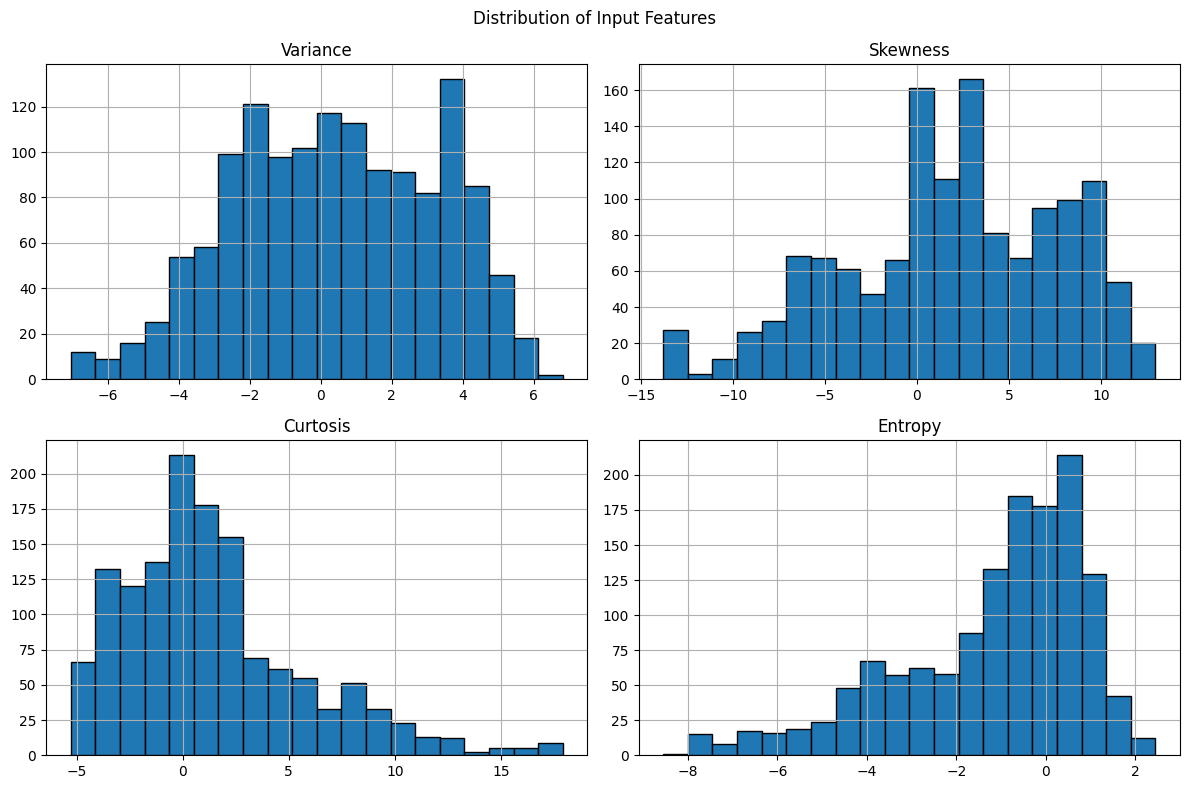

In [ ]:
#histograms
df[["Variance", "Skewness", "Curtosis", "Entropy"]].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Input Features")
plt.tight_layout()
plt.show()

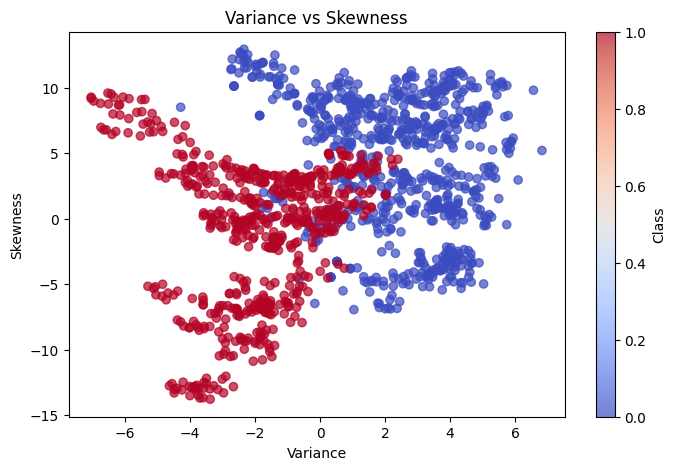

In [ ]:
#first scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Variance"],
    df["Skewness"],
    c=df["Class"],
    cmap="coolwarm",
    alpha=0.7
)

plt.title("Variance vs Skewness")
plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.colorbar(label="Class")
plt.show()

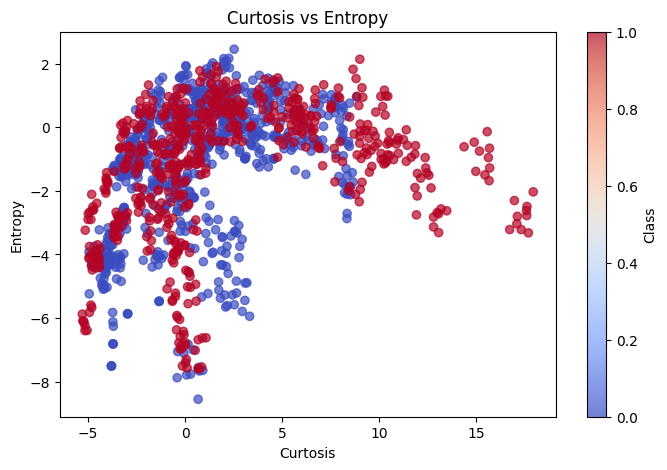

In [ ]:
#second scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Curtosis"],
    df["Entropy"],
    c=df["Class"],
    cmap="coolwarm",
    alpha=0.7
)

plt.title("Curtosis vs Entropy")
plt.xlabel("Curtosis")
plt.ylabel("Entropy")
plt.colorbar(label="Class")
plt.show()

In [ ]:
#stage 4
# Separating input features and target variable

X = df[["Variance", "Skewness", "Curtosis", "Entropy"]]

y = df["Class"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

Input features shape: (1372, 4)
Target variable shape: (1372,)


In [ ]:
#stage 5
#Perform train-test split
# Splitting the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (1097, 4)
Testing data: (275, 4)
Training labels: (1097,)
Testing labels: (275,)


In [ ]:
#stage 6
#Apply StandardScaler
# Feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data shape: (1097, 4)
Scaled testing data shape: (275, 4)


In [ ]:
#stage 7
# Creating the Logistic Regression model

model = LogisticRegression(max_iter=1000)

# Training the model

model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
#stage 8
#Predicting the test data

y_pred = model.predict(X_test_scaled)

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))


#Comparing actual and predicted values

comparison = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred
})

comparison.head(15)
# Generate prediction probabilities

y_prob = model.predict_proba(X_test_scaled)

print("Probability predictions generated successfully!")
print(y_prob[:5])

#Displaying actual, predicted and probability values
probability_results = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred,
    "Probability of Class 0": y_prob[:, 0],
    "Probability of Class 1": y_prob[:, 1]
})

probability_results.head(10)

#Checking correct and incorrect predictions

correct = (y_test.values == y_pred).sum()
incorrect = (y_test.values != y_pred).sum()

print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Total predictions:", len(y_pred))

Predictions generated successfully!
Total predictions: 275
Probability predictions generated successfully!
[[9.99576433e-01 4.23567092e-04]
 [3.35717098e-02 9.66428290e-01]
 [7.55630532e-01 2.44369468e-01]
 [3.55676247e-02 9.64432375e-01]
 [6.95876485e-03 9.93041235e-01]]
Correct predictions: 267
Incorrect predictions: 8
Total predictions: 275


In [ ]:
#stage 9
# Model Evaluation

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

#Complete Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

#Evaluation Metrics Table
evaluation_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

evaluation_results

Model Evaluation Results
Accuracy: 0.9709090909090909
Precision: 0.9384615384615385
Recall: 1.0
F1 Score: 0.9682539682539683
Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.95      0.97       153
           1       0.94      1.00      0.97       122

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



,Metric,Score
0,Accuracy,0.970909
1,Precision,0.938462
2,Recall,1.000000
3,F1-Score,0.968254


Confusion Matrix:
[[145   8]
 [  0 122]]
True Negative (TN): 145
False Positive (FP): 8
False Negative (FN): 0
True Positive (TP): 122


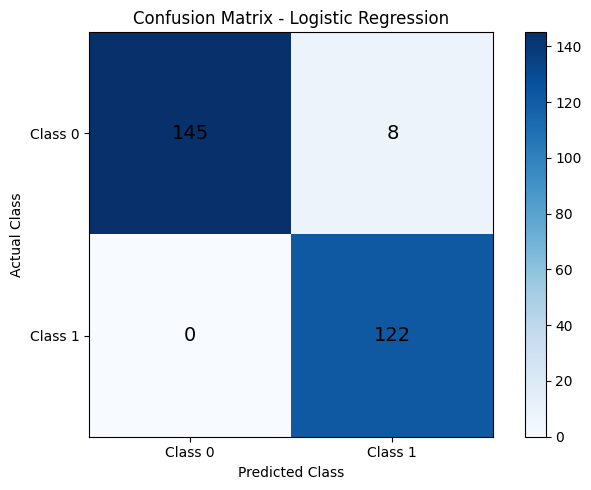

In [ ]:
#stage 10
# Generating Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

#Extracting confusion matrix values
TN, FP, FN, TP = cm.ravel()
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

#Visualising the Confusion Matrix
plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")

plt.title("Confusion Matrix - Logistic Regression")
plt.colorbar()

plt.xticks([0, 1], ["Class 0", "Class 1"])
plt.yticks([0, 1], ["Class 0", "Class 1"])

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center",
                 color="black",
                 fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
#stage 11
thresholds = [0.30, 0.50, 0.70]
threshold_results = []
for threshold in thresholds:
    y_threshold_pred = (y_prob[:, 1] >= threshold).astype(int)
    acc = accuracy_score(y_test, y_threshold_pred)
    prec = precision_score(y_test, y_threshold_pred, zero_division=0)
    rec = recall_score(y_test, y_threshold_pred, zero_division=0)
    f1_value = f1_score(y_test, y_threshold_pred, zero_division=0)
    cm_threshold = confusion_matrix(y_test, y_threshold_pred)
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1_value,
        "Confusion Matrix": cm_threshold.tolist()
    })

print("Threshold analysis completed!")


threshold_comparison = pd.DataFrame(threshold_results)
threshold_comparison[
    ["Threshold", "Accuracy", "Precision", "Recall", "F1-Score"]
]

print(threshold_comparison.to_string(index=False))

for result in threshold_results:
    print("\nThreshold:", result["Threshold"])
    print("Confusion Matrix:")
    print(np.array(result["Confusion Matrix"]))

Threshold analysis completed!
 Threshold  Accuracy  Precision  Recall  F1-Score     Confusion Matrix
       0.3  0.970909   0.938462     1.0  0.968254 [[145, 8], [0, 122]]
       0.5  0.970909   0.938462     1.0  0.968254 [[145, 8], [0, 122]]
       0.7  0.996364   0.991870     1.0  0.995918 [[152, 1], [0, 122]]

Threshold: 0.3
Confusion Matrix:
[[145   8]
 [  0 122]]

Threshold: 0.5
Confusion Matrix:
[[145   8]
 [  0 122]]

Threshold: 0.7
Confusion Matrix:
[[152   1]
 [  0 122]]
